In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)

# Check available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("Available tables:")
display(tables)

# Load selected yield datasets
yield_train = pd.read_sql_query(
    "SELECT * FROM agri_yield_train_selected",
    conn
)

yield_test = pd.read_sql_query(
    "SELECT * FROM agri_yield_test_selected",
    conn
)

conn.close()

print("Training dataset shape:", yield_train.shape)
print("Test dataset shape:", yield_test.shape)

print("\nTraining dataset:")
display(yield_train.head())

print("\nTest dataset:")
display(yield_test.head())

Available tables:


,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected


Training dataset shape: (10000, 11)
Test dataset shape: (2000, 10)

Training dataset:


,NDVI_Temperature,OrganicMatter_Sand,Temperature_Rainfall,sand_pct,NDVI_Rainfall,soil_ph,organic_matter,Humidity_Rainfall,Temperature_Humidity,rainfall,yield
0,11.592,110.656,2777.04,41.6,50.692,6.25,2.66,7714.0,1764.0,110.2,4105.8
1,15.871,147.132,3397.47,40.2,74.517,6.70,3.66,9851.4,2098.2,126.3,4247.8
2,17.664,138.000,3019.44,40.0,70.016,7.21,3.45,7220.4,1821.6,109.4,4021.8
3,18.352,141.112,4596.88,56.9,96.286,5.73,2.48,12268.7,2338.4,155.3,4326.8
4,15.500,110.466,4315.00,30.6,107.012,6.88,3.61,13808.0,2000.0,172.6,3708.0



Test dataset:


,NDVI_Temperature,OrganicMatter_Sand,Temperature_Rainfall,sand_pct,NDVI_Rainfall,soil_ph,organic_matter,Humidity_Rainfall,Temperature_Humidity,rainfall
0,16.740,101.480,4924.35,47.2,105.900,6.25,2.15,14473.0,2287.8,176.5
1,12.500,114.904,4187.50,54.2,83.750,7.40,2.12,12395.0,1850.0,167.5
2,12.556,199.056,4528.92,52.8,66.693,6.96,3.77,11632.5,2190.0,155.1
3,12.465,73.352,3423.72,34.6,55.620,6.70,2.12,10011.6,2243.7,123.6
4,15.936,75.210,4310.19,34.5,110.784,5.81,2.18,14540.4,2091.6,173.1


In [2]:
# Check whether target exists
if "yield" not in yield_train.columns:
    raise ValueError("Target column 'yield' is missing.")

# Separate input features and target
X = yield_train.drop(columns=["yield"])
y = yield_train["yield"]

# Test dataset contains input features only
X_test = yield_test.copy()

print("Training features shape:", X.shape)
print("Target shape:", y.shape)
print("Test features shape:", X_test.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget column:", y.name)

Training features shape: (10000, 10)
Target shape: (10000,)
Test features shape: (2000, 10)

Feature columns:
['NDVI_Temperature', 'OrganicMatter_Sand', 'Temperature_Rainfall', 'sand_pct', 'NDVI_Rainfall', 'soil_ph', 'organic_matter', 'Humidity_Rainfall', 'Temperature_Humidity', 'rainfall']

Target column: yield


In [3]:
print("Missing values in training data:")
display(yield_train.isnull().sum().to_frame(name="Missing Values"))

print("\nMissing values in test data:")
display(yield_test.isnull().sum().to_frame(name="Missing Values"))

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in training data:


,Missing Values
NDVI_Temperature,0
OrganicMatter_Sand,0
Temperature_Rainfall,0
sand_pct,0
NDVI_Rainfall,0
soil_ph,0
organic_matter,0
Humidity_Rainfall,0
Temperature_Humidity,0
rainfall,0



Missing values in test data:


,Missing Values
NDVI_Temperature,0
OrganicMatter_Sand,0
Temperature_Rainfall,0
sand_pct,0
NDVI_Rainfall,0
soil_ph,0
organic_matter,0
Humidity_Rainfall,0
Temperature_Humidity,0
rainfall,0



Missing values in target:
0


In [4]:
print(
    "Duplicate rows in training data:",
    yield_train.duplicated().sum()
)

print(
    "Duplicate rows in test data:",
    yield_test.duplicated().sum()
)

Duplicate rows in training data: 0
Duplicate rows in test data: 0


In [5]:
print("Training data types:")
display(yield_train.dtypes.to_frame(name="Data Type"))

print("\nTest data types:")
display(yield_test.dtypes.to_frame(name="Data Type"))

Training data types:


,Data Type
NDVI_Temperature,float64
OrganicMatter_Sand,float64
Temperature_Rainfall,float64
sand_pct,float64
NDVI_Rainfall,float64
soil_ph,float64
organic_matter,float64
Humidity_Rainfall,float64
Temperature_Humidity,float64
rainfall,float64



Test data types:


,Data Type
NDVI_Temperature,float64
OrganicMatter_Sand,float64
Temperature_Rainfall,float64
sand_pct,float64
NDVI_Rainfall,float64
soil_ph,float64
organic_matter,float64
Humidity_Rainfall,float64
Temperature_Humidity,float64
rainfall,float64


In [6]:
print("Yield summary statistics:")
display(y.describe().to_frame(name="Value"))

print("Number of unique yield values:", y.nunique())
print("Minimum yield:", y.min())
print("Maximum yield:", y.max())
print("Mean yield:", y.mean())
print("Median yield:", y.median())

Yield summary statistics:


,Value
count,10000.000000
mean,4251.976400
std,436.533109
min,3500.200000
25%,3868.050000
50%,4257.150000
75%,4638.325000
max,5000.000000


Number of unique yield values: 7276
Minimum yield: 3500.2
Maximum yield: 5000.0
Mean yield: 4251.9764
Median yield: 4257.15


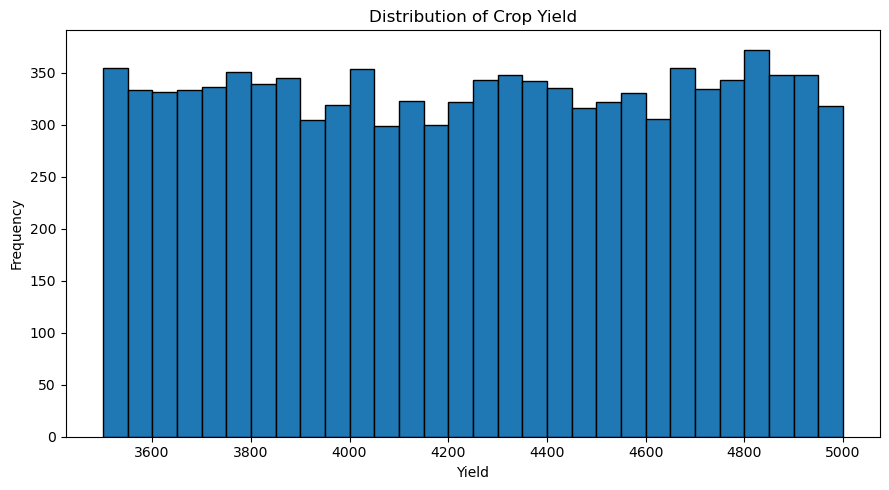

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(y.dropna(), bins=30, edgecolor="black")

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [8]:
train_features = set(X.columns)
test_features = set(X_test.columns)

print("Features missing from test data:")
print(sorted(train_features - test_features))

print("\nExtra features in test data:")
print(sorted(test_features - train_features))

if train_features == test_features:
    print("\nTraining and test features are compatible.")
else:
    print("\nFeature mismatch found. Investigate before training.")

Features missing from test data:
[]

Extra features in test data:
[]

Training and test features are compatible.


In [9]:
print("========== STAGE 13 VALIDATION ==========")

print("Training rows:", len(yield_train))
print("Training features:", X.shape[1])
print("Test rows:", len(X_test))
print("Target missing values:", y.isnull().sum())

print(
    "Training feature missing values:",
    X.isnull().sum().sum()
)

print(
    "Test feature missing values:",
    X_test.isnull().sum().sum()
)

print(
    "Feature columns match:",
    train_features == test_features
)

========== STAGE 13 VALIDATION ==========
Training rows: 10000
Training features: 10
Test rows: 2000
Target missing values: 0
Training feature missing values: 0
Test feature missing values: 0
Feature columns match: True
